In [20]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [21]:
lambda_qcd = 0.241 #GeV
conv_fmGeV = 5.068 # fm to GeV^-1
d = 0.54 * conv_fmGeV # GeV-1 
A = 197 # 197 for Au beam, 208 for Pb beam
conv_mbGeV2 = 2.56819

def RA(A):
    return (1.12 * A**(1/3) - 0.86*A**(-1/3))*conv_fmGeV # return in GeV^-1

def rhoA(z, bt, A): # Woods-Saxon distribution # GeV-1 
    ra = RA(A)
    n = 3.0/(4.0 * np.pi * RA(A)**3) * 1.0/(1.0 + (np.pi * d/RA(A))**2)
    B = (np.sqrt(bt**2 + z**2) - ra)/d
    rhoA = n / (1 + np.exp(B))
    return rhoA

# Woods-Saxon distribution T_A: rhoA integrated over z
def get_TA(bt, A): 
    TA = integrate.quad(rhoA, -999.0, 999.0, args = (bt, A))
    return TA[0]

def dipA(r, bt, A, Qs02, gamma, e_c, sigma0_2): # dipole nucleus
    sigma0_2 = sigma0_2 * 2.56819 # converted to 1/GeV2
    #n = woods_saxon_norm(A)
    #test = integrate.quad(lambda b: 2.0*np.pi*b*get_TA(b, A), 0, np.inf)
    #assert np.isclose(test[0], 1.0, atol=1e-3), "Thickness function not normalized to 1.0"
    TA = get_TA(bt, A) 
    B = A * TA * (sigma0_2)*((r**2)*(Qs02))**gamma
    C = 1/(r*lambda_qcd) + e_c * np.exp(1)
    N = 1 - np.exp(-B/4 * np.log(C))
    #print(TA)
    return N

In [22]:
#load initial condition parameters
ic_qs, ic_ec, ic_c2, ic_sigma02 = np.loadtxt("../data/dipole/posteriorsamples_100_LOmvefit.dat", unpack = True)


In [23]:
#bk_file = "../data/dipole/bk_samplefrommvefit.dat"
bk_file = '../data/nucleus/1/ic_197_0.dat'
BKinterpolator = dipole.BKDipole(bk_file)
#init = [1.0, 0.8, 1.0, 1.0]
init = [1.0, 1.0, 1.0, 1.0]
lbounds = [0.001, 0.1, 1/np.exp(1), 0.001]
ubounds = [10.0, 100.0, 100.0, 10.0]
grid_size = 5 #100
y_max = 8.0
y_array = np.linspace(0, y_max, grid_size)
r = np.logspace(-2, 2, 200)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function

fit_params_array = np.ones((len(y_array), 4))
i = 0
file_params = open("test.dat", "w")
for y in y_array:
    minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds, lsmethod ='trf')
    out = minimizer.fit_ls()
    fit_params = out.x
    fit_params_array[i, :] = fit_params
    if y == 0:
        fit_params_array[i, :] = [ic_qs[0], 1.0, ic_ec[0], 1.0]
        fit_params_array[i, 0] = 197 * get_TA(0, A) * ic_sigma02[0] * conv_mbGeV2 * ic_qs[0]
    #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    print('### y = ', np.round(y,3))
    print(fit_params_array[i, :] )
    #init = fit_params
    i += 1

with file_params:
    file_params.write("# Parameter file of fit of dipole from {}".format(bk_file) + "\n")
    file_params.write("# y ranges from 0 to {} in {} steps".format(y_max, grid_size) + "\n")
    file_params.write("# Columns: y, Qs2, gamma, ec, p" + "\n")
    for j in range(len(y_array)):
        file_params.write("{: .6e} {: .6e} {: .6e} {: .6e} {: .6e}\n".format(y_array[j], fit_params_array[j,0], fit_params_array[j,1], fit_params_array[j,2], fit_params_array[j,3]))

### y =  0.0
[ 0.16900086  1.         58.53206606  1.        ]
### y =  2.0
[0.7059324  1.05389929 0.5578714  0.99182569]
### y =  4.0
[1.26094608 0.92714197 0.36787948 1.08660194]
### y =  6.0
[1.40238766 1.00222233 0.36787945 0.93882329]
### y =  8.0
[1.54648338 1.12414074 0.36787944 0.79064965]


Text(0, 0.5, 'N(r,y)')

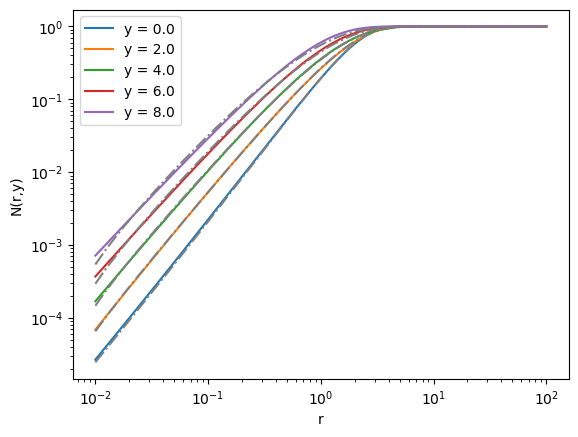

In [24]:
i = 0
for y in y_array:
    fit_params = fit_params_array[i, :]
    fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    plt.plot(r, np.exp(fit_func), '-', label='y = '+str(np.round(y,3)))
    plt.plot(r, np.exp(Nyr(y,r)), '-.', color = 'gray')
    i += 1
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r')
plt.ylabel('N(r,y)')
# plt.ylim(1e-1, 1e1)


## Get Fourier transform

In [25]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(y,k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def log_S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

[1.00000000e-02 1.20679264e-02 1.45634848e-02 1.75751062e-02
 2.12095089e-02 2.55954792e-02 3.08884360e-02 3.72759372e-02
 4.49843267e-02 5.42867544e-02 6.55128557e-02 7.90604321e-02
 9.54095476e-02 1.15139540e-01 1.38949549e-01 1.67683294e-01
 2.02358965e-01 2.44205309e-01 2.94705170e-01 3.55648031e-01
 4.29193426e-01 5.17947468e-01 6.25055193e-01 7.54312006e-01
 9.10298178e-01 1.09854114e+00 1.32571137e+00 1.59985872e+00
 1.93069773e+00 2.32995181e+00 2.81176870e+00 3.39322177e+00
 4.09491506e+00 4.94171336e+00 5.96362332e+00 7.19685673e+00
 8.68511374e+00 1.04811313e+01 1.26485522e+01 1.52641797e+01
 1.84206997e+01 2.22299648e+01 2.68269580e+01 3.23745754e+01
 3.90693994e+01 4.71486636e+01 5.68986603e+01 6.86648845e+01
 8.28642773e+01 1.00000000e+02]


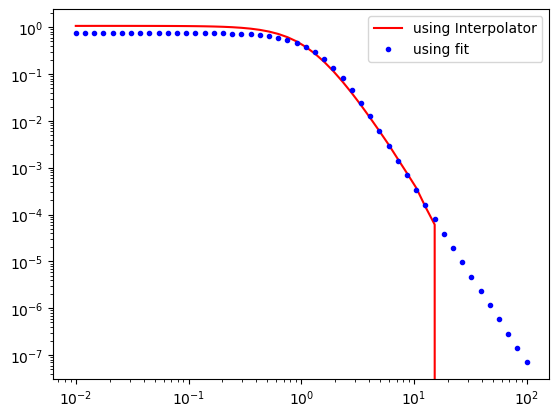

In [26]:
fit_params = fit_params_array[grid_size-1] # last rapidity
k = np.logspace(-2, 2, 50)
print(k)
Sk = S(y_max,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')

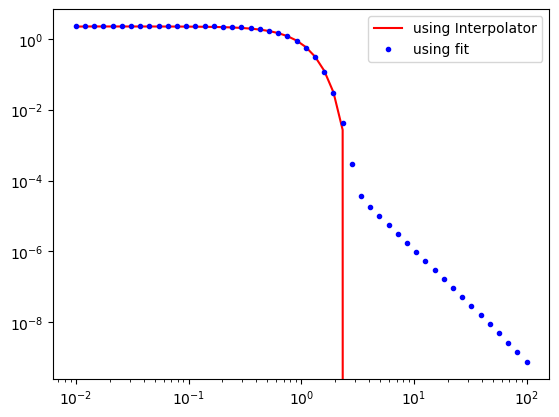

In [27]:
fit_params = fit_params_array[0]
k = np.logspace(-2, 2, 50)
Sk = S(0.0,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')

[ 0.36394409  0.36505287  0.36673109  0.36766828  0.36766858  0.3672759
  0.36701651  0.36699187  0.36703039  0.36700806  0.36693853  0.36686428
  0.36678659  0.36669139  0.36657453  0.36643431  0.36626564  0.36606234
  0.36581749  0.36552256  0.36516732  0.36473944  0.36422405  0.36360326
  0.36285552  0.36195486  0.36087002  0.35956332  0.3579894   0.35609361
  0.35381013  0.35105967  0.34774674  0.34375631  0.33894984  0.33316045
  0.32618714  0.31778779  0.30767082  0.29548497  0.28080721  0.26312798
  0.24183358  0.21618481  0.18529142  0.14808118  0.10326276  0.04928105
 -0.01573665 -0.09404524 -0.18835944 -0.30194678 -0.43873863 -0.60346176
 -0.80179172 -1.04052471 -1.32774898 -1.67294155 -2.08670387 -2.57894291
 -3.15015032 -3.75517485 -4.23775622 -4.49525813 -4.650138   -4.78546654
 -4.91683485 -5.0461729  -5.17402001 -5.30072653 -5.42655375 -5.55170349
 -5.67633579 -5.80058047 -5.92454517 -6.04832105 -6.17198701 -6.29561288
 -6.41926183 -6.54299228 -6.66685938 -6.79091619 -6.

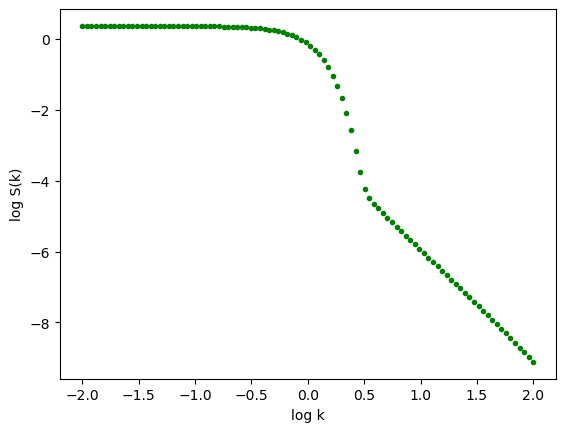

In [28]:
import pandas as pd
k_grid_size = 100#500
log_k_grid = np.linspace(-2, 2, k_grid_size)
log_Sk2 = log_S2(10**log_k_grid, fit_params)
plt.plot(log_k_grid, log_Sk2, '.',label='using fit at y=0.0', color='green')
plt.xlabel('log k')
plt.ylabel('log S(k)')
print(log_Sk2)

In [29]:
y_array_repeat = np.repeat(y_array, k_grid_size)
log_k_min = -2
log_k_max = 2
log_k_all = []
log_Sk2_all = []



for i in range(len(y_array)):
    fit_params = fit_params_array[i, :]
    log_k_grid = np.linspace(log_k_min, log_k_max, k_grid_size)
    log_Sk2 = log_S2(10**log_k_grid, fit_params)
    log_k_all.extend(log_k_grid)
    log_Sk2_all.extend(log_Sk2)

data = {'y': y_array_repeat, 'log10_k':log_k_all, 'log10_S(k)':log_Sk2_all}
df = pd.DataFrame(data)
print(np.shape(y_array_repeat))
print(np.shape(log_k_all))
print(np.shape(log_Sk2_all))

(500,)
(500,)
(500,)


In [30]:
# csv_file = '../data/BKfit_Sk_data.csv'
# comments = ['## Generated from BK dipole with initial condition: MVe model, Q_s0^2 = 0.0544245 GeV^2, \gamma = 1, coefficient of E inside Log is 58.5321',
#                    '## Fitted to file {0}'.format(bk_file),
#                    '## Note definition of log S(k): log_S(k) = log10 S(k) = log10 [ \int r dr J0(k r) (1 - N(r)) ]',
#                    '## log10 k grid ranges from {0} to {1} with {2} points'.format(log_k_min, log_k_max, k_grid_size),
#                    '## y grid ranges from 0 to {0} with {1} points'.format(y_max, grid_size),]

# if save_files:
#     with open(csv_file, 'w') as f:
#         for comment in comments:
#             f.write(comment + '\n')
# df.to_csv(csv_file, index=False, sep = ' ', columns=['y', 'log10_k', 'log10_S(k)'], mode='a', float_format='%.6e') if save_files else None